In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import random
import os
import torch
from torch import nn
from torch.nn import functional as F
from collections import deque

In [2]:
# Note: to learn more about the env please check 01 notebook
# Same Deep Q-learning as frozen lake, but pendulum states are continuous
# the net takes the observation [cos(theta), sin(theta), theta_dot] directly, no bins needed
# DQN outputs one Q value per action, so actions are still discrete torque bins

In [3]:
# Deep Q Network implementation
class DQN(nn.Module):
    def __init__(self, num_states, num_actions) -> None:
        super().__init__()
        self.fc1 = nn.Linear(num_states, 64)
        self.fc2 = nn.Linear(64, 64)
        self.out = nn.Linear(64, num_actions)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.out(x)

# memory for experience replay
class ReplayMemory():
    def __init__(self, maxlen):
        self.memory = deque([], maxlen=maxlen)

    def append(self, transition):
        self.memory.append(transition)

    def sample(self, sample_size):
        return random.sample(self.memory, sample_size)

    def __len__(self):
        return len(self.memory)

# the observation is a numpy array, net input is a float32 tensor
def state_to_dqn_input(state):
    return torch.tensor(state, dtype=torch.float32)

# returns the index of the action bin, the actual torque is action_bins[action_idx]
def epsilon_greedy_action(state, policy_dqn, epsilon):
    if random.uniform(0, 1) < epsilon: # explore
        return random.randrange(num_action_bins)

    else:
        with torch.no_grad():
            # add a batch dimension, (3,) -> (1, 3)
            dqn_input = state_to_dqn_input(state).unsqueeze(0)
            q_values = policy_dqn(dqn_input)
        return q_values.argmax().item() # choose greedy

# one training step of the policy net on a batch from memory
def optimize(discount_factor_g, batch, policy_dqn, target_dqn, loss_fn, optimizer):

    states = torch.stack([state_to_dqn_input(s) for s, a, ns, r, t in batch]) # (batch_size, num_states)
    actions = torch.tensor([a for s, a, ns, r, t in batch], dtype=torch.int64).unsqueeze(-1) # (batch_size, 1) for gather()
    next_states = torch.stack([state_to_dqn_input(ns) for s, a, ns, r, t in batch]) # (batch_size, num_states)
    rewards = torch.tensor([r for s, a, ns, r, t in batch], dtype=torch.float32) # (batch_size,)
    terminated_flags = torch.tensor([float(t) for s, a, ns, r, t in batch], dtype=torch.float32) # (batch_size,)

    # Q(S, A) for the current state and the actions that were taken from that state
    # gather() picks the Q value of the action that was taken
    current_q_values = policy_dqn(states).gather(1, actions).squeeze(-1)

    with torch.no_grad(): # gradients are not needed for the target_dqn as updating only policy_dqn
        # max Q value for the next state from the target net
        next_q_values = target_dqn(next_states).max(1).values
        # the value of a terminal state is 0
        next_q_values[terminated_flags == 1] = 0.0

        # 1 step TD target = reward + gamma * max_a Q_target(S', a)
        target_q_values = rewards + (discount_factor_g * next_q_values)

    loss = loss_fn(current_q_values, target_q_values)

    # learn
    optimizer.zero_grad()
    loss.backward()
    # clip gradients to prevent exploding gradients
    torch.nn.utils.clip_grad_norm_(policy_dqn.parameters(), max_norm=1.0)
    optimizer.step()

In [4]:
# Deep Q-learning
env = gym.make("Pendulum-v1", render_mode=None)

# discretization of action space only, states go to the net directly
num_states = 3 # [cos(theta), sin(theta), theta_dot]
num_action_bins = 5
action_bins = np.linspace(-2.0, 2.0, num_action_bins, dtype=np.float32)

# hyperparameters
num_episodes = 20000 # num of epi to train
discount_factor_g = 0.99

# epsilon decay rate for random exploration
epsilon_start = 1.0 # 100% exploration
epsilon_end = 0.01 # some exploration at the end
epsilon_decay_episodes = num_episodes * 0.8 # epsilon reaches epsilon_end at 80% of episodes
epsilon_decay = (epsilon_start - epsilon_end) / epsilon_decay_episodes

# policy and target dqn
policy_dqn = DQN(num_states=num_states, num_actions=num_action_bins)
target_dqn = DQN(num_states=num_states, num_actions=num_action_bins)
# make target_dqn same as policy_dqn when starting
target_dqn.load_state_dict(policy_dqn.state_dict())

# DQN neural net parameters
batch_size = 256
learning_rate_a = 0.0005
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(policy_dqn.parameters(), lr=learning_rate_a)

network_sync_rate = 10 # after 10 episodes copy the policy net to the target net

# memory for recording transitions
replay_memory_size = 100000
memory = ReplayMemory(replay_memory_size)

# to track reward per episode
reward_per_episode = np.zeros(num_episodes)

for i_episode in range(num_episodes):
    epsilon = max(epsilon_end, epsilon_start - epsilon_decay * i_episode)

    state, info = env.reset()
    terminated = False
    truncated = False
    episode_reward = 0

    # play one episode, save every transition to memory
    while (not terminated and not truncated):
        action_idx = epsilon_greedy_action(state, policy_dqn, epsilon)
        action = action_bins[action_idx]
        next_state, reward, terminated, truncated, info = env.step([action])

        # save action_idx, the net outputs one Q value per action bin
        memory.append((state, action_idx, next_state, reward, terminated))

        state = next_state
        episode_reward += reward

    # keep track of reward at every episode
    reward_per_episode[i_episode] = episode_reward

    # optimize at every end of episode, taking a sample from memory
    # start this when memory size > batch size
    if len(memory) > batch_size:
        batch = memory.sample(batch_size)
        optimize(discount_factor_g, batch, policy_dqn, target_dqn, loss_fn, optimizer)

    # copy the policy net to the target net
    if i_episode % network_sync_rate == 0:
        target_dqn.load_state_dict(policy_dqn.state_dict())

    # progress report
    if (i_episode + 1) % 100 == 0:
        avg_reward = np.mean(reward_per_episode[max(0, i_episode-99):(i_episode+1)])
        print(f"Episode {i_episode+1}/{num_episodes} | Epsilon: {epsilon:.3f} | Avg Reward (last 100): {avg_reward:.2f}")

env.close()

Episode 100/20000 | Epsilon: 0.994 | Avg Reward (last 100): -1213.10
Episode 200/20000 | Epsilon: 0.988 | Avg Reward (last 100): -1253.20
Episode 300/20000 | Epsilon: 0.981 | Avg Reward (last 100): -1231.69
Episode 400/20000 | Epsilon: 0.975 | Avg Reward (last 100): -1225.22
Episode 500/20000 | Epsilon: 0.969 | Avg Reward (last 100): -1343.55
Episode 600/20000 | Epsilon: 0.963 | Avg Reward (last 100): -1250.43
Episode 700/20000 | Epsilon: 0.957 | Avg Reward (last 100): -1322.39
Episode 800/20000 | Epsilon: 0.951 | Avg Reward (last 100): -1293.48
Episode 900/20000 | Epsilon: 0.944 | Avg Reward (last 100): -1295.36
Episode 1000/20000 | Epsilon: 0.938 | Avg Reward (last 100): -1266.09
Episode 1100/20000 | Epsilon: 0.932 | Avg Reward (last 100): -1244.45
Episode 1200/20000 | Epsilon: 0.926 | Avg Reward (last 100): -1181.89
Episode 1300/20000 | Epsilon: 0.920 | Avg Reward (last 100): -1127.45
Episode 1400/20000 | Epsilon: 0.913 | Avg Reward (last 100): -1103.75
Episode 1500/20000 | Epsilon:

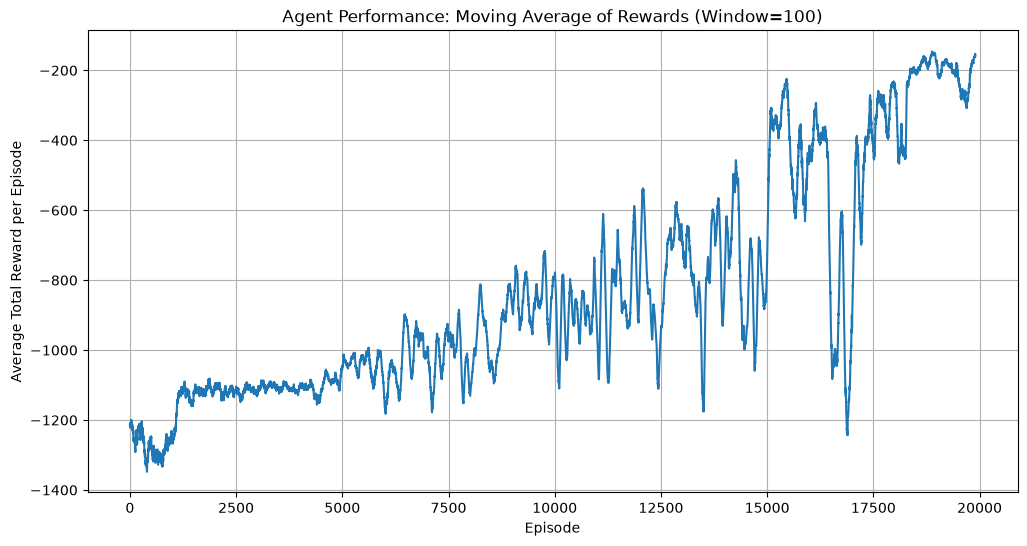

In [5]:
# plotting the moving average of rewards per episode
window_size = 100
moving_avg_rewards = np.convolve(reward_per_episode, np.ones(window_size)/window_size, mode='valid')

plt.figure(figsize=(12, 6))
plt.plot(moving_avg_rewards)
plt.title('Agent Performance: Moving Average of Rewards (Window=100)')
plt.xlabel('Episode')
plt.ylabel('Average Total Reward per Episode')
plt.grid(True)
plt.show()

In [6]:
# Save the learned policy net
policy_filename = 'pendulum_dqn_policy.pt'
torch.save(policy_dqn.state_dict(), policy_filename)

print(f"Policy net saved to {policy_filename}")

Policy net saved to pendulum_dqn_policy.pt


In [7]:
# open the saved policy net
policy_filename = 'pendulum_dqn_policy.pt'

policy_dqn = DQN(num_states=3, num_actions=5)

if os.path.exists(policy_filename):
    policy_dqn.load_state_dict(torch.load(policy_filename))
    policy_dqn.eval() # switch model to evaluation mode
    print(f"Policy net loaded from {policy_filename}")
else:
    print(f"Error: Policy file '{policy_filename}' not found. Please run the training code first.")

Policy net loaded from pendulum_dqn_policy.pt


In [8]:
# Evaluate the learned policy
env = gym.make("Pendulum-v1", render_mode='human')

print("Evaluating learned policy...")
total_rewards = 0
num_eval_episodes = 3

for _ in range(num_eval_episodes):
    state, info = env.reset()
    terminated = False
    truncated = False
    episode_reward = 0

    while (not terminated and not truncated):
        # For evaluation, use a greedy policy (no exploration)
        with torch.no_grad():
            action_idx = policy_dqn(state_to_dqn_input(state).unsqueeze(0)).argmax().item()
        action = action_bins[action_idx]
        next_state, reward, terminated, truncated, info = env.step([action])
        episode_reward += reward
        state = next_state

    total_rewards += episode_reward
print(f"Average reward over {num_eval_episodes} evaluation episodes: {total_rewards / num_eval_episodes:.4f}")
env.close()

Evaluating learned policy...
Average reward over 3 evaluation episodes: -240.8178
